# EDA de precios del maíz blanco | Cobertura y faltantes

## La preguntita inicial
¿Qué información tenemos disponible por mes, mercado y origen
durante la ventana de 2013–2025?

Cada fila representa un mes, un mercado y un origen del maíz.
El precio está expresado en pesos mexicanos por kilogramo.
Los precios faltantes se conservarán, de momento, sin imputación.

In [2]:
from pathlib import Path

import pandas as pd

# Ubicamos la raíz desde el repositorio o desde notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

# Cargamos los datos y reconocemos la fecha como tal.
ruta = raiz / "data" / "processed" / "sniim_maiz_blanco_mensual.csv"
datos = pd.read_csv(ruta, parse_dates=["fecha"])

# Observamos las primeras filas, sin transformar los precios.
datos.head(10)

,fecha,estado_mercado,mercado,origen,producto,precio_mxn_kg
0,2013-01-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.36
1,2013-02-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.00
2,2013-03-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.50
3,2013-04-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.24
4,2013-05-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.62
5,2013-06-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.30
6,2013-07-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.56
7,2013-08-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.40
8,2013-09-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.32
9,2013-10-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.72


## Estructura general de los datos

¿Cuántas observaciones y columnas tenemos?
¿Qué tipos de datos tienen las columnas y cuántos valores
están presentes en cada una?

In [3]:
# Revisamos dimensiones, tipos y cantidad de valores presentes.
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   fecha           960 non-null    datetime64[us]
 1   estado_mercado  960 non-null    str           
 2   mercado         960 non-null    str           
 3   origen          960 non-null    str           
 4   producto        960 non-null    str           
 5   precio_mxn_kg   791 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(4)
memory usage: 81.7 KB


### Observación inicial

El conjunto contiene 960 observaciones y seis columnas.
Cada observación corresponde a un mes, mercado y origen.

La única columna con valores faltantes es `precio_mxn_kg`:
tiene 791 precios presentes y 169 faltantes (17.6 %).

Este conteo todavía no distingue entre un origen sin precio
y un mercado sin ningún precio disponible durante un mes.

In [4]:
# Identificamos el periodo y los mercados presentes.
print("Primera fecha:", datos["fecha"].min().date())
print("Última fecha:", datos["fecha"].max().date())
print("Meses distintos:", datos["fecha"].nunique())
print("Mercados:", sorted(datos["mercado"].unique()))

Primera fecha: 2013-01-01
Última fecha: 2025-12-01
Meses distintos: 156
Mercados: ['Culiacán', 'Guadalajara', 'Guadalupe', 'Hermosillo', 'Iztapalapa']


## Cobertura por mercado

¿Cuántos meses aparecen para cada mercado y cuántos precios
están disponibles?

Un mercado puede tener varias filas en un mismo mes cuando
se registran distintos orígenes del maíz de manera simultánea.

In [5]:
# Resumimos las filas, los meses y los precios por mercado.
resumen_mercados = datos.groupby("mercado").agg(
    filas=("fecha", "size"),
    meses_registrados=("fecha", "nunique"),
    precios_presentes=("precio_mxn_kg", "count"),
)

# Calculamos cuántas filas tienen el precio vacío.
resumen_mercados["precios_faltantes"] = (
    resumen_mercados["filas"] - resumen_mercados["precios_presentes"]
)

resumen_mercados

,filas,meses_registrados,precios_presentes,precios_faltantes
mercado,,,,
Culiacán,204,156,160,44
Guadalajara,192,156,158,34
Guadalupe,216,156,166,50
Hermosillo,168,156,151,17
Iztapalapa,180,156,156,24


In [9]:
# Contamos precios disponibles entre los orígenes de cada mercado y mes.
cobertura_mensual = (
    datos.groupby(["mercado", "fecha"])
    .agg(numero_precios=("precio_mxn_kg", "count"))
    .reset_index()
)

# Identificamos los meses sin ningún precio disponible.
meses_sin_precio = cobertura_mensual.loc[
    cobertura_mensual["numero_precios"] == 0
].copy()

print(meses_sin_precio)
print(f"Se tienen {len(meses_sin_precio)} meses sin precio alguno")

         mercado      fecha  numero_precios
89      Culiacán 2020-06-01               0
245  Guadalajara 2020-06-01               0
401    Guadalupe 2020-06-01               0
402    Guadalupe 2020-07-01               0
536   Hermosillo 2018-09-01               0
537   Hermosillo 2018-10-01               0
538   Hermosillo 2018-11-01               0
539   Hermosillo 2018-12-01               0
540   Hermosillo 2019-01-01               0
557   Hermosillo 2020-06-01               0
713   Iztapalapa 2020-06-01               0
720   Iztapalapa 2021-01-01               0
Se tienen 12 meses sin precio alguno


### Hallazgo sobre los datos faltantes

Al considerar todos los orígenes de cada mercado, se identifican
12 combinaciones mercado–mes sin ningún precio disponible.

Hermosillo presenta cinco meses consecutivos sin precio,
de septiembre de 2018 a enero de 2019. También destaca la
ausencia simultánea de precios en los cinco mercados en junio
de 2020.

Estos huecos se conservarán, de momento, como faltantes en el análisis
principal. Su causa no puede determinarse únicamente con
los archivos disponibles.

Si bien, son pocos datos faltantes significativos a priori entre sí, al expandir un estudio utilizando esta misma arquitectura necesitaría de una estructura de analizar descriptivamente esos espacios vacíos.

In [10]:
# Marcamos los meses que no tienen ningún precio disponible.
cobertura_mensual["sin_precio"] = (
    cobertura_mensual["numero_precios"] == 0
)

# Contamos meses registrados y meses sin precio por mercado.
resumen_cobertura = cobertura_mensual.groupby("mercado").agg(
    meses_registrados=("fecha", "nunique"),
    meses_sin_precio=("sin_precio", "sum"),
)

# Expresamos los meses sin precio como porcentaje de los registrados.
resumen_cobertura["porcentaje_sin_precio"] = (
    100
    * resumen_cobertura["meses_sin_precio"]
    / resumen_cobertura["meses_registrados"]
)

resumen_cobertura.round(2)

,meses_registrados,meses_sin_precio,porcentaje_sin_precio
mercado,,,
Culiacán,156,1,0.64
Guadalajara,156,1,0.64
Guadalupe,156,2,1.28
Hermosillo,156,6,3.85
Iztapalapa,156,2,1.28


## Visualización de la disponibilidad mensual

¿Los meses sin precio aparecen aislados, consecutivos o
simultáneamente en varios mercados?

Cada celda representa un mercado y un mes. Los colores
indican si existe al menos un precio disponible.

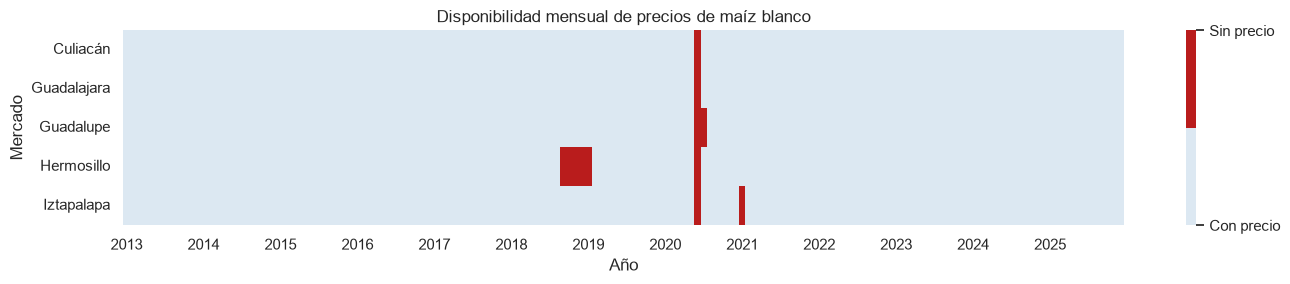

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Organizamos los faltantes en filas de mercados y columnas de meses.
matriz_faltantes = cobertura_mensual.pivot(
    index="mercado",
    columns="fecha",
    values="sin_precio",
).sort_index(axis=1)

# Dibujamos la disponibilidad: cero indica presencia y uno ausencia.
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(14, 3))

sns.heatmap(
    matriz_faltantes.astype(int),
    cmap=["#dce8f2", "#b91c1c"],
    vmin=0,
    vmax=1,
    xticklabels=12,
    yticklabels=True,
    cbar_kws={"ticks": [0, 1]},
    ax=ax,
)

# Etiquetamos los años y explicamos los colores.
ax.set_xticklabels(
    matriz_faltantes.columns[::12].strftime("%Y"),
    rotation=0,
)
ax.tick_params(axis="y", labelrotation=0)
ax.set_title("Disponibilidad mensual de precios de maíz blanco")
ax.set_xlabel("Año")
ax.set_ylabel("Mercado")

barra = ax.collections[0].colorbar
barra.set_ticklabels(["Con precio", "Sin precio"])

fig.tight_layout()
plt.show()

Como los faltantes están concentrados en una ventana central del rango, veamos la misma gráfica pero por año desmenuzando por mes.

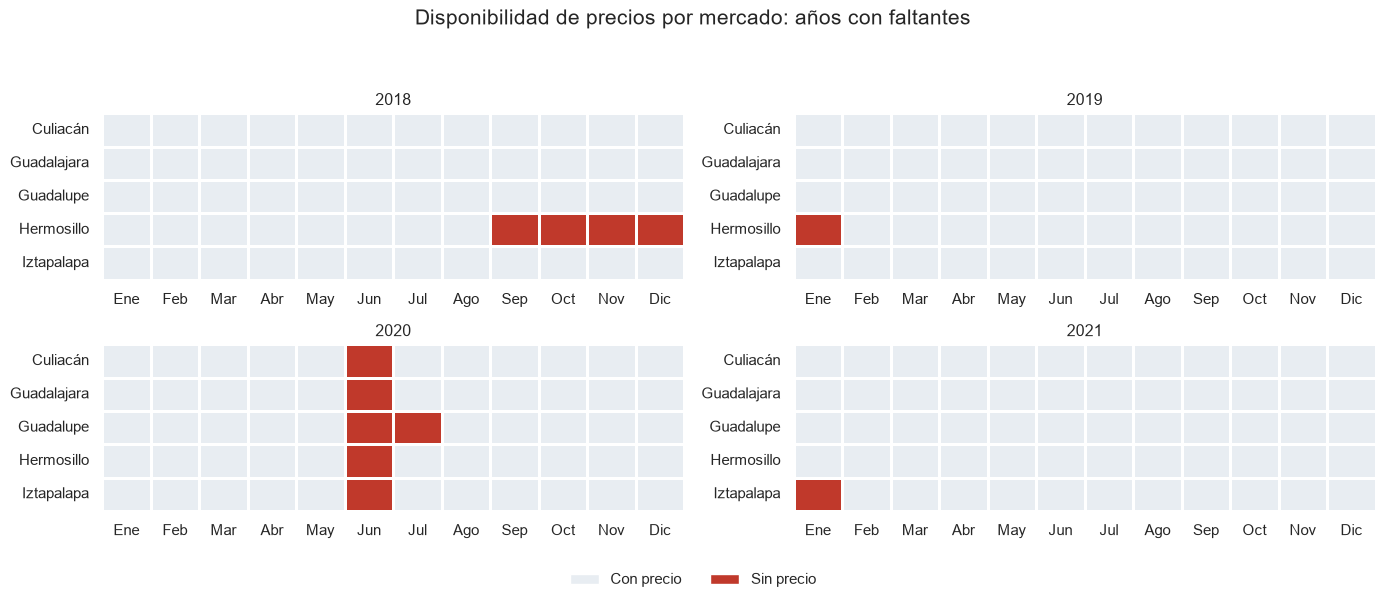

In [12]:
from matplotlib.patches import Patch

# Seleccionamos los años que contienen meses sin precio.
anios = sorted(meses_sin_precio["fecha"].dt.year.unique())
meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]
colores = ["#e8edf2", "#c0392b"]

# Creamos un panel para cada año.
sns.set_theme(style="white", font_scale=0.95)
fig, ejes = plt.subplots(2, 2, figsize=(14, 6))

for anio, ax in zip(anios, ejes.flat):
    # Organizamos los meses del año por mercado.
    anual = cobertura_mensual.loc[
        cobertura_mensual["fecha"].dt.year == anio
    ].copy()
    anual["mes"] = anual["fecha"].dt.month

    matriz = anual.pivot(
        index="mercado",
        columns="mes",
        values="sin_precio",
    ).sort_index(axis=1)

    # Usamos los mismos colores y escala en todos los paneles.
    sns.heatmap(
        matriz.astype(int),
        cmap=colores,
        vmin=0,
        vmax=1,
        cbar=False,
        linewidths=1,
        linecolor="white",
        xticklabels=meses,
        yticklabels=True,
        ax=ax,
    )

    ax.set(title=str(anio), xlabel="", ylabel="")
    ax.tick_params(axis="both", labelrotation=0)

# Añadimos un título y una leyenda compartidos.
fig.suptitle(
    "Disponibilidad de precios por mercado: años con faltantes",
    fontsize=15,
)
fig.legend(
    handles=[
        Patch(facecolor=colores[0], label="Con precio"),
        Patch(facecolor=colores[1], label="Sin precio"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
)

fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

## Construcción del precio mensual por mercado

¿Cómo obtenemos un solo precio cuando existen varios
orígenes en un mismo mercado y mes?

Calcularemos el promedio simple de los precios disponibles,
asignando el mismo peso a cada origen. Conservaremos también
la cantidad de precios utilizados.

Si ningún origen tiene precio, el promedio permanecerá
como dato faltante.

In [13]:
# Calculamos el promedio y contamos los precios utilizados por mercado y mes.
precios_mensuales = (
    datos.groupby(["mercado", "fecha"], as_index=False)
    .agg(
        precio_promedio_mxn_kg=("precio_mxn_kg", "mean"),
        numero_precios=("precio_mxn_kg", "count"),
    )
)

# Observamos la estructura de la nueva tabla.
precios_mensuales.head(10)

,mercado,fecha,precio_promedio_mxn_kg,numero_precios
0,Culiacán,2013-01-01,4.50,1
1,Culiacán,2013-02-01,4.50,1
2,Culiacán,2013-03-01,4.70,1
3,Culiacán,2013-04-01,4.58,1
4,Culiacán,2013-05-01,4.00,1
5,Culiacán,2013-06-01,4.00,1
6,Culiacán,2013-07-01,4.00,1
7,Culiacán,2013-08-01,4.00,1
8,Culiacán,2013-09-01,4.25,2
9,Culiacán,2013-10-01,4.20,1


In [16]:
# Contamos meses con cero, uno o varios precios disponibles.
precios_mensuales["numero_precios"].value_counts().sort_index()

numero_precios
0     12
1    746
2     21
3      1
Name: count, dtype: int64

In [17]:
# Consultamos los precios originales que participaron en este promedio.
datos.loc[
    (datos["mercado"] == "Culiacán")
    & (datos["fecha"] == "2013-09-01"),
    ["fecha", "mercado", "origen", "precio_mxn_kg"],
]

,fecha,mercado,origen,precio_mxn_kg
176,2013-09-01,Culiacán,Sinaloa,4.0
188,2013-09-01,Culiacán,Jalisco,4.5


## Análisis de las tendencias temporales
¿Qué tendencias, diferencias entre mercados y cambios abruptos aparecen durante 2013–2025?

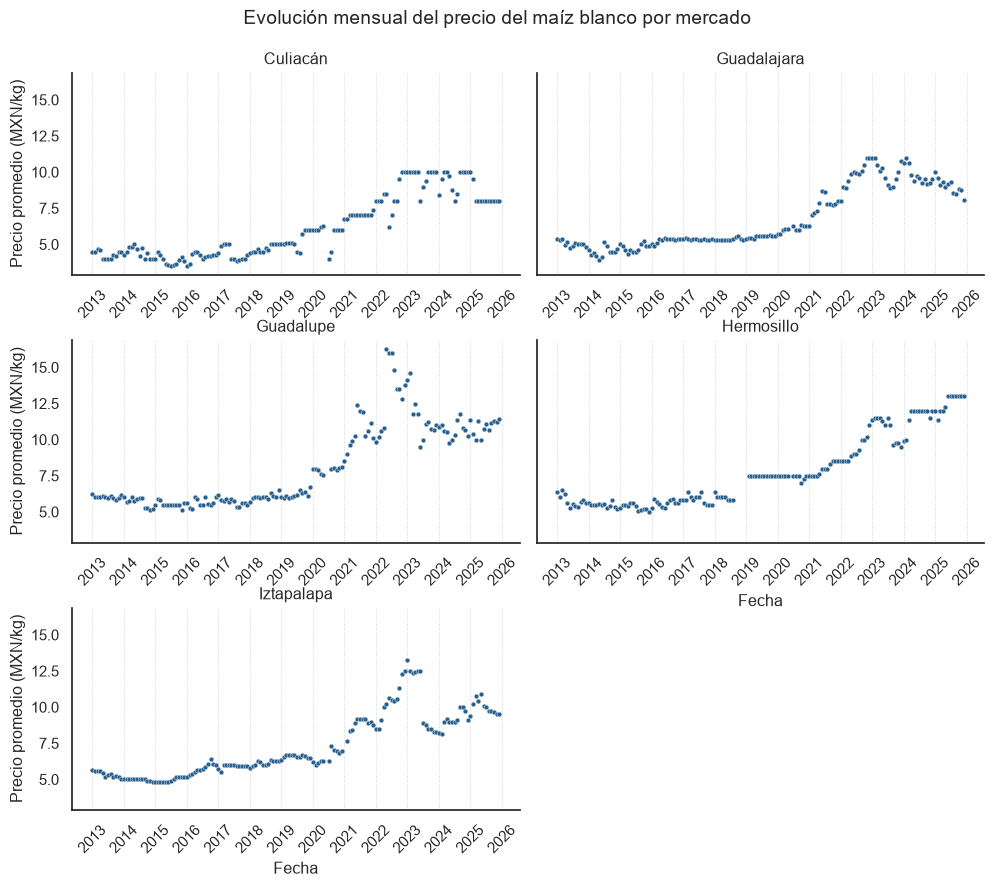

In [21]:
# Creamos un panel por mercado con sus precios mensuales.
grafica = sns.relplot(
    data=precios_mensuales,
    x="fecha",
    y="precio_promedio_mxn_kg",
    col="mercado",
    col_wrap=2,
    kind="scatter",
    height=2.8,
    aspect=1.8,
    s=12,
    color="#286090",
)

# Mantenemos escalas comunes para comparar los mercados.
grafica.set_axis_labels("Fecha", "Precio promedio (MXN/kg)")
grafica.set_titles("{col_name}")
grafica.figure.suptitle(
    "Evolución mensual del precio del maíz blanco por mercado",
    y=1.03,
)

import matplotlib.dates as mdates

# Marcamos cada año con una línea vertical tenue.
for ax in grafica.axes.flat:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_axisbelow(True)
    ax.grid(
        axis="x",
        linestyle=":",
        linewidth=0.7,
        color="gray",
        alpha=0.35,
    )
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)


plt.show()

Podemos observar tres patrones:
- Antes de 2020, los precios se mantienen en niveles estables y con fluctuaciones aparentemente moderadas.
- Entrr 2020 y 2023, aparece un aumento en los cinco mercados, aunque no con la misma intensidad y momento de estabilización.
- Después de los máximos, las trayectorias divergen: casi todos los mercados bajan un poco después del pico alrededor de 2023, mientras que Hermosillo continúa la tendencia de elevar los precios al final de cada año.

## Resumen descriptivo de los precios mensuales

¿Cuáles son los precios centrales, los extremos y la
variabilidad de cada mercado durante el periodo analizado?

In [23]:
# Resumimos los precios mensuales disponibles en cada mercado.
resumen_precios = precios_mensuales.groupby("mercado").agg(
    meses_con_precio=("precio_promedio_mxn_kg", "count"),
    media=("precio_promedio_mxn_kg", "mean"),
    mediana=("precio_promedio_mxn_kg", "median"),
    desviacion_estandar=("precio_promedio_mxn_kg", "std"),
    minimo=("precio_promedio_mxn_kg", "min"),
    maximo=("precio_promedio_mxn_kg", "max"),
)

resumen_precios.round(2)

,meses_con_precio,media,mediana,desviacion_estandar,minimo,maximo
mercado,,,,,,
Culiacán,155,6.12,5.00,2.14,3.50,10.00
Guadalajara,155,6.78,5.58,2.11,3.90,11.00
Guadalupe,154,8.12,6.23,2.85,5.12,16.25
Hermosillo,150,7.83,7.50,2.49,5.00,13.00
Iztapalapa,154,7.31,6.35,2.19,4.80,13.25


Lo que podemos observar a priori es:
- Guadalupe tiene la mayor media, el mayor máximo, el mayor mínimo y la mayor desviación estándar.
- Hermosillo cuenta con la mayor mediana.
- Culiacán presenta los menores valores de media, mediana y mínimo
- En todos los mercados, la media supera a la mediana.


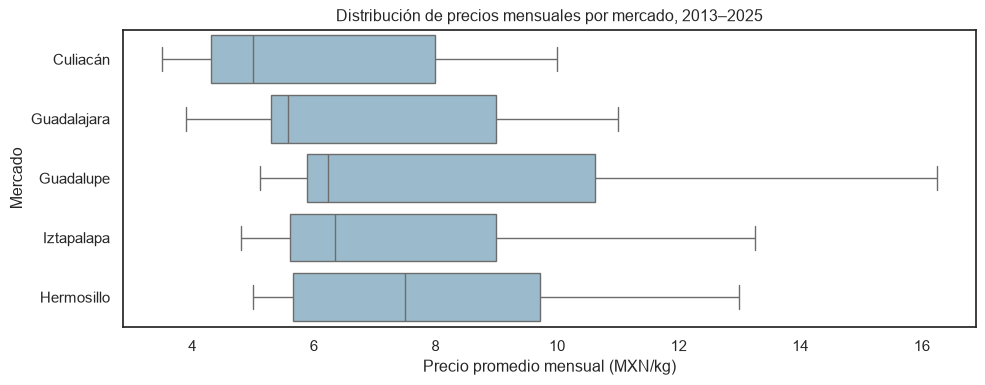

In [24]:
# Ordenamos los mercados según su precio mediano.
orden = resumen_precios.sort_values("mediana").index

# Comparamos las distribuciones de los precios mensuales.
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=precios_mensuales,
    x="precio_promedio_mxn_kg",
    y="mercado",
    order=orden,
    color="#93bdd5",
    whis=1.5,
    ax=ax,
)

ax.set_title("Distribución de precios mensuales por mercado, 2013–2025")
ax.set_xlabel("Precio promedio mensual (MXN/kg)")
ax.set_ylabel("Mercado")

fig.tight_layout()
plt.show()

En sí, tiene sentido que no existan datos atípicos, pues al estar revisando un periodo de 13 años completos de principio a fin, los saltos en precios pasan desapercibidos en esta gran ventana. Es por ello que mejor analizaremos las variaciones mensuales.


¿En qué meses el precio aumentó o disminuyó con mayor intensidad respecto al mes anterior?

Esta variación la calcuremos así:

$$
\text{Variación mensual (\%)} = \left( \frac{\text{precio actual}}{\text{precio del mes anterior}} - 1 \right) \times 100
$$

In [25]:
# Ordenamos los registros cronológicamente dentro de cada mercado.
precios_mensuales = precios_mensuales.sort_values(
    ["mercado", "fecha"]
).copy()

# Calculamos variaciones por mercado sin rellenar los precios faltantes.
precios_mensuales["variacion_mensual_pct"] = (
    precios_mensuales.groupby("mercado")["precio_promedio_mxn_kg"]
    .pct_change(fill_method=None)
    .mul(100)
)

# Revisamos los precios y sus variaciones durante los primeros meses.
precios_mensuales[
    [
        "mercado",
        "fecha",
        "precio_promedio_mxn_kg",
        "variacion_mensual_pct",
    ]
].head(12)

,mercado,fecha,precio_promedio_mxn_kg,variacion_mensual_pct
0,Culiacán,2013-01-01,4.50,NaN
1,Culiacán,2013-02-01,4.50,0.000000
2,Culiacán,2013-03-01,4.70,4.444444
3,Culiacán,2013-04-01,4.58,-2.553191
4,Culiacán,2013-05-01,4.00,-12.663755
5,Culiacán,2013-06-01,4.00,0.000000
6,Culiacán,2013-07-01,4.00,0.000000
7,Culiacán,2013-08-01,4.00,0.000000
8,Culiacán,2013-09-01,4.25,6.250000
9,Culiacán,2013-10-01,4.20,-1.176471


La nueva columna es correcta:
- En enero aparece NaN, porque no tenemos diciembree de 2012 en el dataset
- Febrero tiene 0 porque el precio se mantuvo igual
- Marzo 4.44 % porque el precio aumentó ese porcentaje.
- Mayo -12.66 % porque el precio bajó abruptamente.

Analicemos las variaciones por mercado a continuación:

¿cuándo aparecen los aumentos y disminuciones más pronunciados?

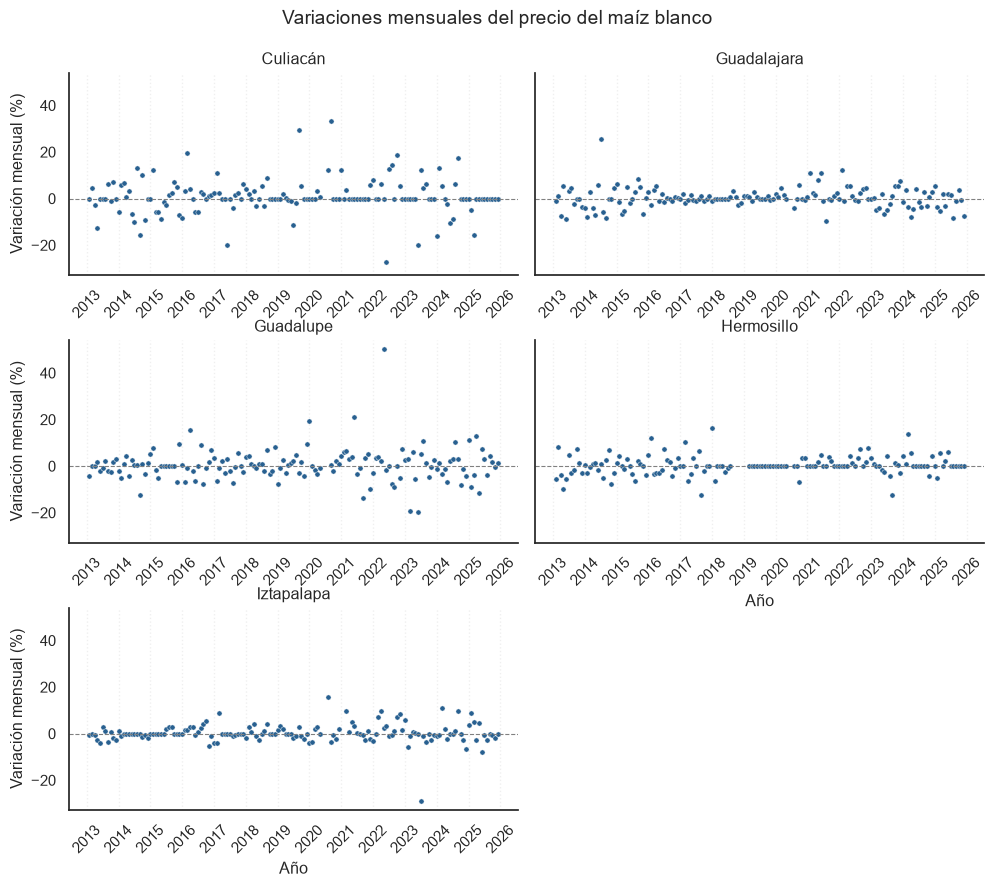

In [27]:
# Mostramos las variaciones mensuales en un panel por mercado.
grafica_variaciones = sns.relplot(
    data=precios_mensuales,
    x="fecha",
    y="variacion_mensual_pct",
    col="mercado",
    col_wrap=2,
    kind="scatter",
    height=2.8,
    aspect=1.8,
    s=14,
    color="#286090",
)

# Marcamos la ausencia de cambio y las referencias anuales.
for ax in grafica_variaciones.axes.flat:
    ax.axhline(
        0, color="gray", linestyle="--", linewidth=0.8
    )
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_axisbelow(True)
    ax.grid(axis="x", linestyle=":", alpha=0.3)
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)

grafica_variaciones.set_axis_labels("Año", "Variación mensual (%)")
grafica_variaciones.set_titles("{col_name}")
grafica_variaciones.figure.suptitle(
    "Variaciones mensuales del precio del maíz blanco",
    y=1.03,
)

plt.show()

Podemos distinguir cambios mensuales pronunciados en Culaicán, Guadalupe e Iztapalapa. En Hermosillo aparecen muchos meses donde no se movió el precio. Analizaremos posibles outliers por mercado basándonos en los meses.

In [28]:
# Calculamos los cuartiles de las variaciones de cada mercado.
limites_iqr = (
    precios_mensuales.groupby("mercado")["variacion_mensual_pct"]
    .agg(
        q1=lambda serie: serie.quantile(0.25),
        q3=lambda serie: serie.quantile(0.75),
    )
)

# Construimos el rango intercuartílico y los límites de detección.
limites_iqr["iqr"] = limites_iqr["q3"] - limites_iqr["q1"]

limites_iqr["limite_inferior"] = (
    limites_iqr["q1"] - 1.5 * limites_iqr["iqr"]
)
limites_iqr["limite_superior"] = (
    limites_iqr["q3"] + 1.5 * limites_iqr["iqr"]
)

# Mostramos los límites como porcentajes de variación mensual.
limites_iqr.round(2)

,q1,q3,iqr,limite_inferior,limite_superior
mercado,,,,,
Culiacán,0.00,3.33,3.33,-5.00,8.33
Guadalajara,-1.29,2.44,3.73,-6.89,8.03
Guadalupe,-2.56,3.21,5.77,-11.22,11.86
Hermosillo,-0.70,1.66,2.36,-4.25,5.21
Iztapalapa,-0.93,1.61,2.54,-4.73,5.41


Se puede observar que entre Culiacán y Hermosillo, ésta última tiene un rango más estrecho, por lo que un aumento de un mes a otro del 7 % sí sería outlier en Hermosillo, pero no en Culiacán. Veamos esto por cada mercado:

In [39]:
# Asociamos cada observación con los límites de su mercado.
revision_iqr = precios_mensuales.merge(
    limites_iqr.reset_index(),
    on="mercado",
    how="left",
    validate="many_to_one",
)

# Seleccionamos variaciones observadas que quedan fuera de los límites.
candidatos_iqr = revision_iqr.loc[
    revision_iqr["variacion_mensual_pct"].notna()
    & (
        (
            revision_iqr["variacion_mensual_pct"]
            < revision_iqr["limite_inferior"]
        )
        | (
            revision_iqr["variacion_mensual_pct"]
            > revision_iqr["limite_superior"]
        )
    ),
    [
        "mercado",
        "fecha",
        "variacion_mensual_pct",
        "limite_inferior",
        "limite_superior",
    ],
].copy()

# Redondeamos únicamente las columnas numéricas para mostrarlas.
vista_iqr = candidatos_iqr.copy()
columnas_numericas = vista_iqr.select_dtypes(include="number").columns

vista_iqr[columnas_numericas] = vista_iqr[columnas_numericas].round(2)

vista_iqr

,mercado,fecha,variacion_mensual_pct,limite_inferior,limite_superior
4,Culiacán,2013-05-01,-12.66,-5.00,8.33
12,Culiacán,2014-01-01,-5.56,-5.00,8.33
17,Culiacán,2014-06-01,-6.70,-5.00,8.33
18,Culiacán,2014-07-01,-9.97,-5.00,8.33
19,Culiacán,2014-08-01,13.10,-5.00,8.33
...,...,...,...,...,...
758,Iztapalapa,2024-03-01,10.84,-4.73,5.41
764,Iztapalapa,2024-09-01,9.65,-4.73,5.41
767,Iztapalapa,2024-12-01,-6.67,-4.73,5.41
769,Iztapalapa,2025-02-01,8.81,-4.73,5.41


Al tener 104 candidatos a revisión, hay que resumirlos por mercado y porcentaje representado.

In [41]:
# Contamos las variaciones disponibles para evaluar en cada mercado.
resumen_iqr = precios_mensuales.groupby("mercado").agg(
    variaciones_evaluables=("variacion_mensual_pct", "count")
)

# Contamos los candidatos; cero significa que ninguno fue señalado.
resumen_iqr["candidatos_iqr"] = (
    candidatos_iqr.groupby("mercado")
    .size()
    .reindex(resumen_iqr.index, fill_value=0)
)

# Calculamos el porcentaje sobre las variaciones evaluables.
resumen_iqr["porcentaje_candidatos"] = (
    100
    * resumen_iqr["candidatos_iqr"]
    / resumen_iqr["variaciones_evaluables"]
)

resumen_iqr.round(2)

,variaciones_evaluables,candidatos_iqr,porcentaje_candidatos
mercado,,,
Culiacán,153,37,24.18
Guadalajara,153,14,9.15
Guadalupe,152,10,6.58
Hermosillo,147,27,18.37
Iztapalapa,151,16,10.60


Se puede ver que Culiacán es quien registra mayor proporción de candidatos, teniendo variaciones bruscas en 37 meses, le sigue Hermosillo con 27, mientras que Guadalupe es más discreto haciéndolo solamente 10 veces en su propia dimensión (su rango es más amplio).

Veremos cuáles son los candidatos más grande tanto en aumentos abruptos como en disminuciones.

In [42]:
# Medimos el tamaño del cambio sin importar su dirección.
candidatos_ordenados = candidatos_iqr.copy()

candidatos_ordenados["magnitud_cambio"] = (
    candidatos_ordenados["variacion_mensual_pct"].abs()
)

# Ordenamos de mayor a menor magnitud.
candidatos_ordenados = candidatos_ordenados.sort_values(
    "magnitud_cambio",
    ascending=False,
)

# Revisamos los diez cambios más pronunciados.
candidatos_ordenados.head(10)

,mercado,fecha,variacion_mensual_pct,limite_inferior,limite_superior,magnitud_cambio
424,Guadalupe,2022-05-01,50.184843,-11.215173,11.861564,50.184843
92,Culiacán,2020-09-01,33.333333,-5.000000,8.333333,33.333333
80,Culiacán,2019-09-01,29.545455,-5.000000,8.333333,29.545455
750,Iztapalapa,2023-07-01,-28.960000,-4.732843,5.414404,28.960000
113,Culiacán,2022-06-01,-27.058824,-5.000000,8.333333,27.058824
174,Guadalajara,2014-07-01,25.755744,-6.887319,8.034830,25.755744
413,Guadalupe,2021-06-01,20.975610,-11.215173,11.861564,20.975610
53,Culiacán,2017-06-01,-20.000000,-5.000000,8.333333,20.000000
125,Culiacán,2023-06-01,-20.000000,-5.000000,8.333333,20.000000
38,Culiacán,2016-03-01,19.502075,-5.000000,8.333333,19.502075


Vemos que el mayor cambio señalado se sucitó en Guadalupe, en mayo de 2022, cuando con respecto a abril se vio un incremento del 50.18 %. La caída más importante fue Iztapalapa, cuando en julio de 2023 el precio cayó en 28.96 % con respecto al mes de junio. 

Queremos ver si el salto en los precios es de un mismo origin o si coincide con aquellos meses donde promediamos los precios al tener 2 o más orígenes, para esto veremos solamente el caso de Guadalupe:

In [43]:
# Consultamos los precios por origen antes y durante el mayor aumento.
caso_guadalupe = datos.loc[
    (datos["mercado"] == "Guadalupe")
    & datos["fecha"].between("2022-04-01", "2022-05-01"),
    ["fecha", "mercado", "origen", "precio_mxn_kg"],
].sort_values(["fecha", "origen"])

caso_guadalupe

,fecha,mercado,origen,precio_mxn_kg
915,2022-04-01,Guadalupe,Tamaulipas,10.82
916,2022-05-01,Guadalupe,Tamaulipas,16.25


### Revisión de un candidato detectado mediante IQR

En Guadalupe, el precio aumentó de 10.82 a 16.25 MXN/kg
entre abril y mayo de 2022, una variación de 50.18 %.

Ambos registros corresponden al origen Tamaulipas y existe
un único precio disponible en cada mes. Por tanto, el aumento
no surge de promediar distintos orígenes.

Los valores coinciden con el HTML conservado del SNIIM.
En junio de 2022 el precio permanece elevado, en 16.00 MXN/kg.

Se conserva la observación y su identificación como candidato
IQR. El cotejo no permite determinar la causa económica del cambio.